In [1]:
import torch
import torchvision
from torchvision import transforms, datasets, models
import torch.nn as nn
import torch.optim as optim
from sklearn.metrics import classification_report
from pathlib import Path

from sklearn.metrics import precision_score,confusion_matrix,accuracy_score,ConfusionMatrixDisplay
import matplotlib.pyplot as plt

print(torch.__version__)
print(torchvision.__version__)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

2.9.0+cu128
0.24.0+cu128
Device: cuda


In [2]:
dataset_path = Path("/home/pongo/project/computer_vision/Medical Waste.v1i.folder/")

train_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(10),
    transforms.ColorJitter(0.2, 0.2, 0.2),
    transforms.ToTensor(),
    transforms.Normalize([0.485,0.456,0.406],[0.229,0.224,0.225])
])

test_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize([0.485,0.456,0.406],[0.229,0.224,0.225])
])

train_dataset = datasets.ImageFolder(dataset_path/"train", transform=train_transform)
val_dataset   = datasets.ImageFolder(dataset_path/"valid", transform=test_transform)
test_dataset  = datasets.ImageFolder(dataset_path/"test", transform=test_transform)

train_loader = torch.utils.data.DataLoader(train_dataset, batch_size=32, shuffle=True)
val_loader   = torch.utils.data.DataLoader(val_dataset, batch_size=32, shuffle=False)
test_loader  = torch.utils.data.DataLoader(test_dataset, batch_size=32, shuffle=False)

class_names = train_dataset.classes
num_classes = len(class_names)

print("Classes:", class_names)

Classes: ['gloves', 'masks', 'medicine', 'syringe']


In [3]:
from collections import Counter

# Menghitung jumlah data tiap kelas
train_count = Counter(train_dataset.targets)
val_count = Counter(val_dataset.targets)
test_count = Counter(test_dataset.targets)

print("=== Train Dataset ===")
for idx, cls in enumerate(class_names):
    print(f"{cls:<15}: {train_count[idx]}")

print("\n=== Validation Dataset ===")
for idx, cls in enumerate(class_names):
    print(f"{cls:<15}: {val_count[idx]}")

print("\n=== Test Dataset ===")
for idx, cls in enumerate(class_names):
    print(f"{cls:<15}: {test_count[idx]}")

=== Train Dataset ===
gloves         : 714
masks          : 1156
medicine       : 675
syringe        : 731

=== Validation Dataset ===
gloves         : 112
masks          : 207
medicine       : 114
syringe        : 115

=== Test Dataset ===
gloves         : 59
masks          : 105
medicine       : 63
syringe        : 51


In [4]:
def build_model(model_name, num_classes):

    if model_name == "resnet50":
        model = models.resnet50(weights=models.ResNet50_Weights.IMAGENET1K_V1)
        model.fc = nn.Linear(model.fc.in_features, num_classes)

    elif model_name == "mobilenetv2":
        model = models.mobilenet_v2(weights=models.MobileNet_V2_Weights.IMAGENET1K_V1)
        model.classifier[1] = nn.Linear(model.classifier[1].in_features, num_classes)

    elif model_name == "efficientnet":
        model = models.efficientnet_b0(weights=models.EfficientNet_B0_Weights.IMAGENET1K_V1)
        model.classifier[1] = nn.Linear(model.classifier[1].in_features, num_classes)

    else:
        raise ValueError("Model not supported")

    return model.to(device)

In [5]:
def evaluate(model, loader, criterion):

    model.eval()

    running_loss = 0

    y_true = []
    y_pred = []

    with torch.no_grad():

        for x, y in loader:

            x = x.to(device)
            y = y.to(device)

            outputs = model(x)

            loss = criterion(outputs, y)

            running_loss += loss.item()

            preds = torch.argmax(outputs, dim=1)

            y_true.extend(y.cpu().numpy())
            y_pred.extend(preds.cpu().numpy())

    loss = running_loss / len(loader)

    acc = accuracy_score(y_true, y_pred)

    return loss, acc, y_true, y_pred


def train(model, train_loader, val_loader, epochs=10):

    criterion = nn.CrossEntropyLoss()

    optimizer = optim.Adam(
        model.parameters(),
        lr=1e-4,
        weight_decay=1e-4
    )

    history = {
        "train_loss": [],
        "val_loss": [],
        "train_acc": [],
        "val_acc": []
    }

    for epoch in range(epochs):

        model.train()

        running_loss = 0

        y_true_train = []
        y_pred_train = []

        for x, y in train_loader:

            x = x.to(device)
            y = y.to(device)

            optimizer.zero_grad()

            outputs = model(x)

            loss = criterion(outputs, y)

            loss.backward()

            optimizer.step()

            running_loss += loss.item()

            preds = torch.argmax(outputs, 1)

            y_true_train.extend(y.cpu().numpy())
            y_pred_train.extend(preds.cpu().numpy())

        train_loss = running_loss / len(train_loader)

        train_acc = accuracy_score(
            y_true_train,
            y_pred_train
        )

        val_loss, val_acc, _, _ = evaluate(
            model,
            val_loader,
            criterion
        )

        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)
        history["train_acc"].append(train_acc)
        history["val_acc"].append(val_acc)

        print(
            f"Epoch {epoch+1}/{epochs}"
            f" | Train Loss {train_loss:.4f}"
            f" | Val Loss {val_loss:.4f}"
            f" | Train Acc {train_acc*100:.2f}%"
            f" | Val Acc {val_acc*100:.2f}%"
        )

    return model, history

In [6]:
models_dict = {}

criterion = nn.CrossEntropyLoss()

for name in ["resnet50", "mobilenetv2", "efficientnet"]:

    print("\n" + "="*50)
    print(f"Training Model : {name.upper()}")
    print("="*50)

    model = build_model(name, num_classes)

    trained_model, history = train(
        model,
        train_loader,
        val_loader,
        epochs=10
    )

    test_loss, test_acc, y_true, y_pred = evaluate(
        trained_model,
        test_loader,
        criterion
    )

    print("\n----- Test Result -----")
    print(f"Test Loss     : {test_loss:.4f}")
    print(f"Test Accuracy : {test_acc*100:.2f}%")

    print("\nClassification Report")
    print(
        classification_report(
            y_true,
            y_pred,
            target_names=class_names
        )
    )

    models_dict[name] = {
        "model": trained_model,
        "history": history,
        "accuracy": test_acc,
        "loss": test_loss
    }


Training Model : RESNET50
Epoch 1/10 | Train Loss 0.3041 | Val Loss 0.2390 | Train Acc 90.17% | Val Acc 91.61%
Epoch 2/10 | Train Loss 0.1188 | Val Loss 0.2727 | Train Acc 96.15% | Val Acc 91.61%
Epoch 3/10 | Train Loss 0.1138 | Val Loss 0.2593 | Train Acc 96.46% | Val Acc 92.34%
Epoch 4/10 | Train Loss 0.0717 | Val Loss 0.2292 | Train Acc 97.62% | Val Acc 93.25%
Epoch 5/10 | Train Loss 0.0607 | Val Loss 0.2807 | Train Acc 98.11% | Val Acc 91.97%
Epoch 6/10 | Train Loss 0.0792 | Val Loss 0.2403 | Train Acc 97.62% | Val Acc 93.43%
Epoch 7/10 | Train Loss 0.0516 | Val Loss 0.2465 | Train Acc 98.47% | Val Acc 93.98%
Epoch 8/10 | Train Loss 0.0401 | Val Loss 0.3183 | Train Acc 98.78% | Val Acc 93.61%
Epoch 9/10 | Train Loss 0.0311 | Val Loss 0.3059 | Train Acc 99.08% | Val Acc 93.25%
Epoch 10/10 | Train Loss 0.0311 | Val Loss 0.3248 | Train Acc 99.21% | Val Acc 93.07%

----- Test Result -----
Test Loss     : 0.2502
Test Accuracy : 94.24%

Classification Report
              precision    r

In [7]:
print("\nClassification Report")

print(
    classification_report(
        y_true,
        y_pred,
        target_names=class_names
    )
)


Classification Report
              precision    recall  f1-score   support

      gloves       0.93      0.93      0.93        59
       masks       0.96      0.95      0.96       105
    medicine       0.98      0.92      0.95        63
     syringe       0.88      0.96      0.92        51

    accuracy                           0.94       278
   macro avg       0.94      0.94      0.94       278
weighted avg       0.94      0.94      0.94       278



In [17]:
models_dict[name] = {
    "accuracy": test_acc,
    "model": trained_model,
    "history": history
}

best_model_name = max(
    models_dict,
    key=lambda x: models_dict[x]["accuracy"]
)

best_model = models_dict[best_model_name]["model"]
best_history = models_dict[best_model_name]["history"]

best_model_name

'resnet50'

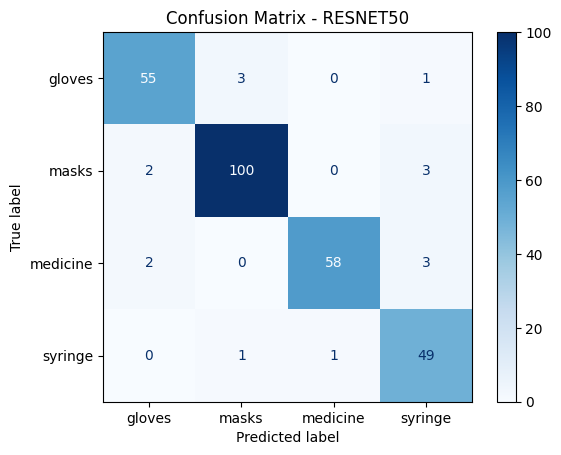

In [20]:
cm = confusion_matrix(y_true, y_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
)

disp.plot(cmap="Blues")
plt.title(f"Confusion Matrix - {best_model_name.upper()}")
plt.show()

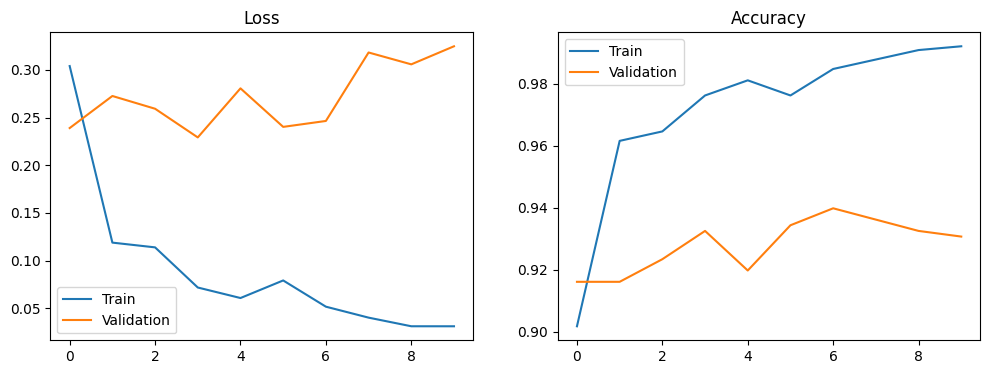

In [21]:
plt.figure(figsize=(12,4))

plt.subplot(1,2,1)
plt.plot(best_history["train_loss"], label="Train")
plt.plot(best_history["val_loss"], label="Validation")
plt.title("Loss")
plt.legend()

plt.subplot(1,2,2)
plt.plot(best_history["train_acc"], label="Train")
plt.plot(best_history["val_acc"], label="Validation")
plt.title("Accuracy")
plt.legend()

plt.show()

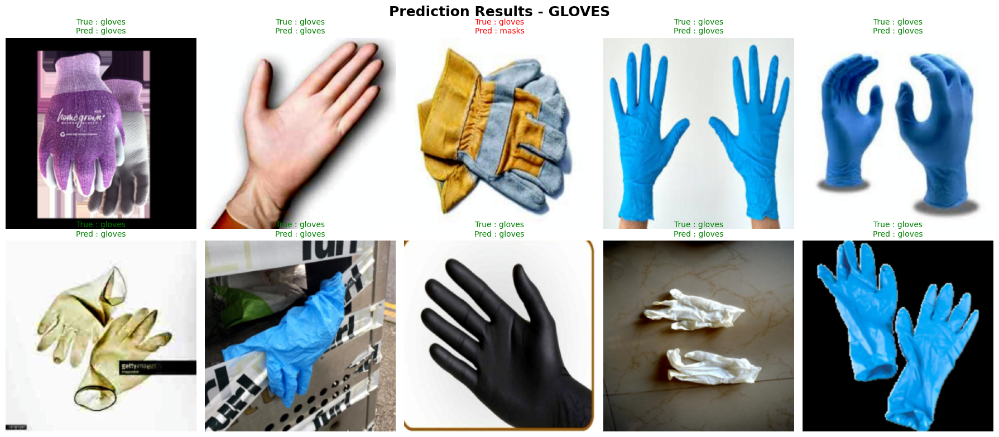

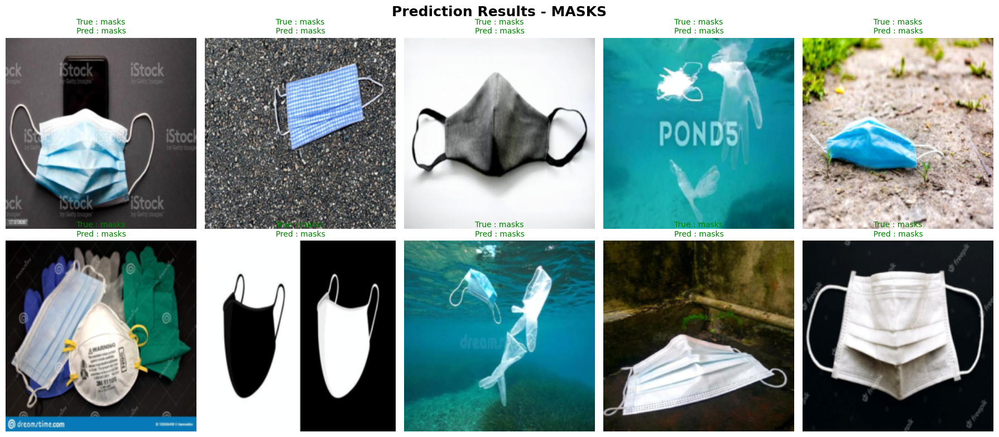

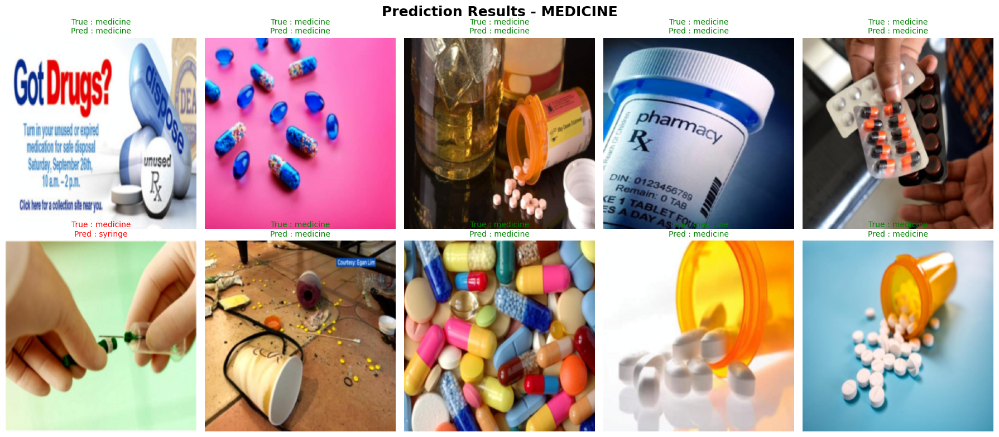

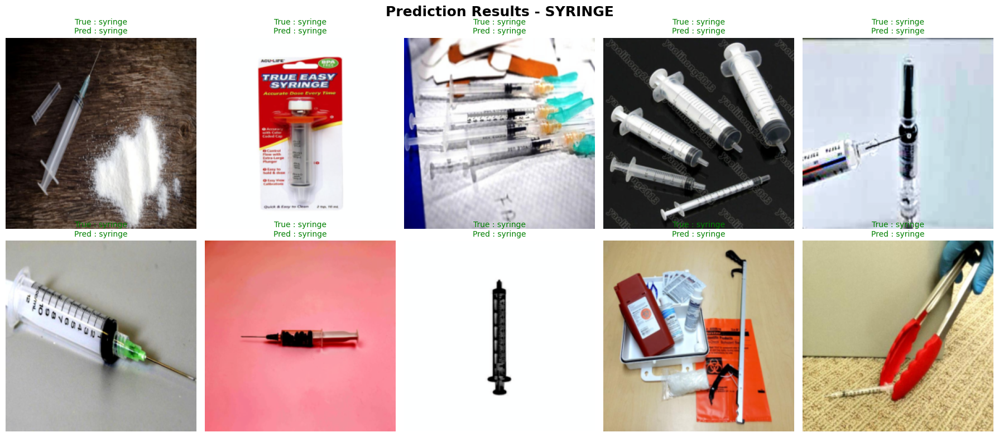

In [23]:
import random
import matplotlib.pyplot as plt
import numpy as np

best_model.eval()

mean = np.array([0.485, 0.456, 0.406])
std = np.array([0.229, 0.224, 0.225])

# Ambil indeks tiap kelas
class_indices = {cls: [] for cls in class_names}

for idx, (_, label) in enumerate(test_dataset.samples):
    class_name = class_names[label]
    class_indices[class_name].append(idx)

# Tampilkan 10 gambar dari setiap kelas
for class_name in class_names:

    indices = random.sample(class_indices[class_name], 10)

    fig = plt.figure(figsize=(18,8))
    fig.suptitle(
        f"Prediction Results - {class_name.upper()}",
        fontsize=18,
        fontweight="bold"
    )

    for i, idx in enumerate(indices):

        image, label = test_dataset[idx]

        img = image.permute(1,2,0).numpy()
        img = img * std + mean
        img = np.clip(img,0,1)

        input_tensor = image.unsqueeze(0).to(device)

        with torch.no_grad():
            output = best_model(input_tensor)
            pred = torch.argmax(output,1).item()

        pred_name = class_names[pred]
        true_name = class_names[label]

        ax = plt.subplot(2,5,i+1)

        ax.imshow(img)

        color = "green" if pred==label else "red"

        ax.set_title(
            f"True : {true_name}\nPred : {pred_name}",
            color=color,
            fontsize=10
        )

        ax.axis("off")

    plt.tight_layout()
    plt.show()

In [24]:

best_model.eval()

mean = np.array([0.485, 0.456, 0.406])
std = np.array([0.229, 0.224, 0.225])

# Menyimpan indeks gambar yang benar dan salah untuk tiap kelas
results = {}

for cls in class_names:
    results[cls] = {
        "correct": [],
        "wrong": []
    }

# Evaluasi seluruh test dataset
with torch.no_grad():

    for idx in range(len(test_dataset)):

        image, label = test_dataset[idx]

        output = best_model(image.unsqueeze(0).to(device))

        pred = torch.argmax(output, 1).item()

        true_class = class_names[label]

        if pred == label:
            results[true_class]["correct"].append((idx, pred))
        else:
            results[true_class]["wrong"].append((idx, pred))

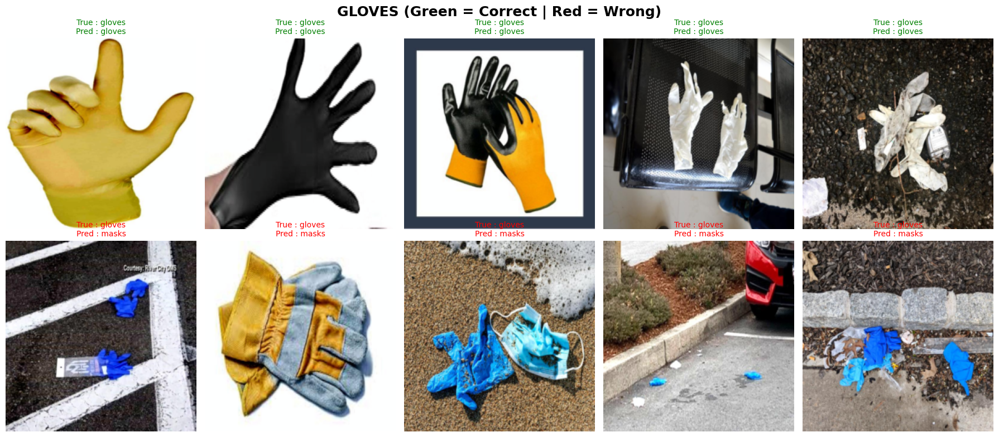

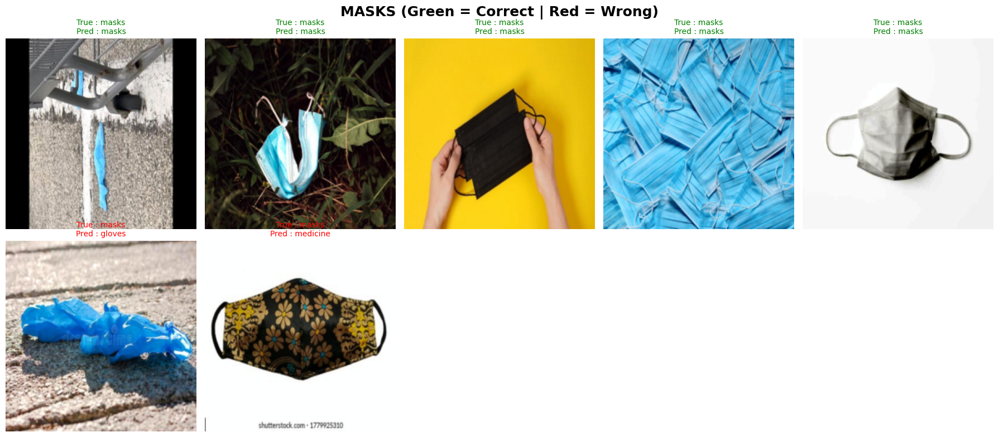

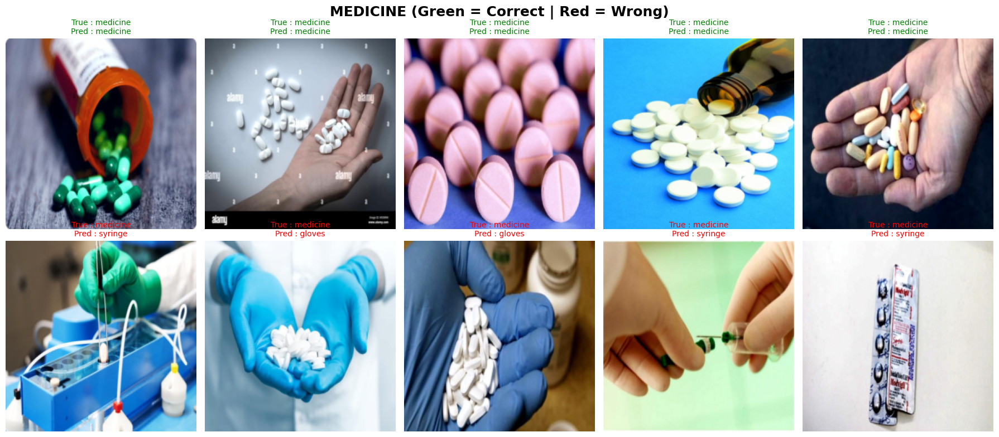

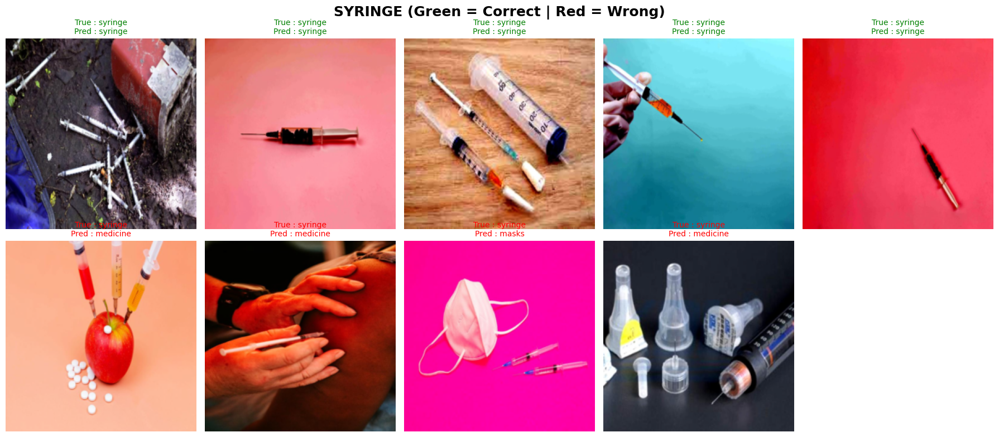

In [25]:
for cls in class_names:

    correct = results[cls]["correct"][:5]
    wrong = results[cls]["wrong"][:5]

    samples = correct + wrong

    fig = plt.figure(figsize=(18,8))

    fig.suptitle(
        f"{cls.upper()} (Green = Correct | Red = Wrong)",
        fontsize=18,
        fontweight="bold"
    )

    for i, (idx, pred) in enumerate(samples):

        image, label = test_dataset[idx]

        img = image.permute(1,2,0).numpy()
        img = img * std + mean
        img = np.clip(img,0,1)

        ax = plt.subplot(2,5,i+1)

        ax.imshow(img)

        color = "green" if pred == label else "red"

        ax.set_title(
            f"True : {class_names[label]}\nPred : {class_names[pred]}",
            color=color,
            fontsize=10
        )

        ax.axis("off")

    plt.tight_layout()
    plt.show()